## Oblique tearing in 3D, with and without shear flow: per-$(k_y,k_z)$ blocks of the autodiff Jacobian

**Rung 2b item 4 of `plans/AUTODIFF_PLAN.md`.** RMHD in normalized Alfvén units: guide field $B_0=1$ along $z$ ($v_A=1$ along $z$),
a 1D sheet $\mathbf b_0=f(x)\hat y$ ($B_y=\partial_x\psi_0$), a flow $\mathbf u_0=u(x)\hat y$, $S=1/\eta$, $\nu=P_m/S$, `hyper=1`, fp64.
A perturbation $\propto e^{ik_yy+ik_zz}$ is resonant where $\mathbf k\cdot\mathbf B=k_yf(x_s)+k_z=0$, i.e. **off the field null**, at
$$f(x_s)=c\equiv-k_z/k_y .$$
(The sign is taranis' and is gated: `tests/test_tearing_oblique.py` locates the current peak of the tearing vector at $x_s=\operatorname{atanh}c$.)

**Numerics.** `dims=3`, `z_spectral=True`, $n_z=4$ (the 2/3 rule keeps $|i_z|=1$), $n_y=8$, a $z$-independent $x_0$, and the
$(k_y,k_z)$ block `ky_block_*(x0, ..., iky=1, iz=iz)`: `iz=1` is $k_z=+2\pi/L_z$, `iz=3` is $k_z=-2\pi/L_z$, `iz=0` is $k_z=0$.
One `Parameters` per $(n_x,L_x)$ serves every point: $k_y$, $k_z$ and `diss` move through the overrides seam,
`overrides={"Ly": 2π/k, "Lz": 2π/|kz|, "diss": (Pm/S, 1/S)}` (gated against a `Parameters` built at that point: 0 to round-off).
Solver: `tearing_ofman_run`'s ladder — a dense seed (`np.linalg.eigvals` of the block), then band-LU-preconditioned `shift_invert`
rungs doubling $n_x$ until two agree to $10^{-6}$; the harness's own residual gate against the exact 3D operator on every pair.
Data: `examples/tearing_oblique_run.py` (every solve one cache file under `examples/data/tearing-oblique/`); this notebook only reads.

Profiles:
* **pair** — rung 1b-ref's exact periodic tanh pair, $B_y=\tanh(x-L_x/4)$ and $-\tanh(x-3L_x/4)$ locally (the Harris sheet, $|f'(0)|=1$,
  $\Delta'a=2(1/ka-ka)$ at $c=0$). With $c\neq0$ sheet 1 resonates at $L_x/4+\operatorname{atanh}c$, sheet 2 at $3L_x/4-\operatorname{atanh}c$.
  The pair profile is even about $0$ and $L_x/2$, so the two pair members are still even/odd about the midpoint; **we report the member of
  larger $\mathrm{Re}\,\lambda$ (always the even one here)** and store the parity and the split. $L_x=\max(40,16/k)$.
* **sech2** — rungs 1a/2's single sheet $\Psi_0=\mathrm{sech}^2x$ ($f=-2\tanh\mathrm{sech}^2$, $|f'(0)|=2$), $L_x=20/k$, for continuity with
  `tearing-viscosity.ipynb` and `tearing-lowk-branch.ipynb`. $f$ is not monotonic: for $0<|c|<4/(3\sqrt3)=0.770$, $f=c$ has a central root
  ($|f'|\approx2$) **and** a tail root on the far side ($|f'|\approx2|c|$) — two resonant surfaces.

In [1]:
import os
os.environ["TARANIS_PRECISION"] = "64"
os.environ.setdefault("TARANIS_OBL_PROFILE", "full")
import time
import numpy as np
import matplotlib.pyplot as plt
import tearing_oblique_run as B
T, O = B.T, B.O

t0 = time.time()
LAY = B.results(B.layer_points())
SYM = B.results(B.sym_points())
LOC = B.results(B.local_points())
BOX = B.results(B.box_points())
K0 = B.scan_results("kmax0")
KA = B.scan_results("kmaxA")
VI = B.scan_results("visc")
LK = B.scan_results("lowk")
FD = B.fd_results()
recs = list(LAY.values()) + list(SYM.values()) + list(LOC.values()) + list(BOX.values()) + \
    [x for d in (K0, KA, VI, LK) for r in d.values() for x in r["rows"].values()]
nconv = sum(bool(x["converged"]) for x in recs)
print(f"profile {B.PROFILE}: {len(recs)} ladder points read, {nconv} converged to CONV_TOL = {B.CONV_TOL:g} "
      f"(the rest: section 5's alpha = 0.9, c = 0 scan and section 6's (0.3, 2), c = 0 point) ({time.time() - t0:.1f} s)")

field variables are using 64bit precision.
profile full: 129 ladder points read, 120 converged to CONV_TOL = 1e-06 (the rest: section 5's alpha = 0.9, c = 0 scan and section 6's (0.3, 2), c = 0 point) (10.5 s)


### 1. Theory

**Linearised equations** (the form of `B.fd_oblique`, i.e. Ofman et al. 1991's eqs. 4–5 with $kF\to k_yF+k_z$; the FD code is gated against
taranis' blocks, so these are taranis' equations), $\nabla^2=\partial_x^2-k_y^2$:
$$\gamma\psi=ik_y(f-c)\,\phi-ik_yu\,\psi+\eta\nabla^2\psi,$$
$$\gamma\nabla^2\phi=ik_y(f-c)\nabla^2\psi-ik_yf''\psi-ik_yu\nabla^2\phi+ik_yu''\phi+\nu\nabla^4\phi .$$
**$k_z$ never appears except through $f-c$.** RMHD's perpendicular Laplacian has no $k_z^2$ and taranis' dissipation is perpendicular
(`z_diss_k=0`), so:

**Exact reduction.** The $(k_y,k_z)$ block of $(f,u)$ *is* the $k_z=0$ block of the profile $f-c$ — the same sheet with a uniform $B_y=-c$
added, i.e. the guide field tilted — with the same flow. In particular, for **field-aligned flow** $u=\alpha f=\alpha(f-c)+\alpha c$:
$$\lambda(k_y,k_z;\,f,\alpha f)=\lambda_{2D}\big(k_y;\,f-c,\ \alpha(f-c)\big)-ik_y\alpha c ,$$
because a uniform flow only Doppler shifts. So with aligned flow (i) $\alpha$ is the same at every surface — "α evaluated locally at $x_s$" holds
identically; (ii) $\mathrm{Im}\,\lambda=-k_yu_0(x_s)$ plus whatever the asymmetric problem $f-c$ gives intrinsically; (iii) the oblique question is
the 2D question on an **asymmetric-magnitude** sheet ($|B_y|\to1-c$ and $1+c$ for tanh). For an odd $f$ ($x\to-x$ maps $f+c$ to $-(f-c)$), the
$\pm k_z$ blocks are degenerate without flow and complex conjugates with aligned flow (both gated exactly). A non-aligned flow breaks the
reduction: $\alpha_{loc}(x_s)=u'(x_s)/f'(x_s)$ then varies with $c$ (section 5).

**Outer region** ($\alpha=0$): $\psi''=[k^2+f''/(f-c)]\psi$, singular at $x_s$ with $r=f''(x_s)/f'(x_s)\neq0$ when $c\neq0$. Frobenius:
$\psi=A[1+r\,s\ln|s|+\tfrac12(q-\tfrac32r^2)s^2]+B[s+\tfrac r2s^2+\dots]$, $s=x-x_s$, $q=k^2+f'''/f'-r^2/2$. The log has the same coefficient on both
sides, so $\Delta'=B_+/A-B_-/A$ is convention-free (`B.dprime_iso`: shooting from $\pm30$ to $x_s\pm\epsilon$ with this start; $\epsilon$-independent
to $10^{-8}$). There is no closed form for $c\neq0$ (for tanh the equation in $T=\tanh x$ has singular points $T=\pm1,c,\infty$: Heun; a
polynomial solution needs $c=0$). Two exact limits:
* $c=0$, tanh: $\Delta'=2(1/k-k)$ (Furth, Killeen & Rosenbluth 1963).
* **small $k$, any profile** with $f(\pm\infty)=f_\pm$ (matching $e^{\mp kx}$ to the $k=0$ solutions $f-c$ and $(f-c)\int(f-c)^{-2}$):
  $$k\Delta'\to A(c)=f'(x_s)^2\Big[\frac1{(f_+-c)^2}+\frac1{(f_--c)^2}\Big]\qquad(\text{tanh: }A=2(1+c^2)).$$

**Layer.** At large $S$ the inner layer sees only $k_y|f'(x_s)|$ (and $\alpha$): the exact nonconstant-$\psi$ relation of rung 1a (Coppi et al. 1976;
Boldyrev & Loureiro 2018 eq. 60), $\Delta'\delta_\eta=F(\Lambda)$, with $k|f'(0)|\to k_y|f'(x_s)|$ and $\Delta'\to\Delta'(k_y,c)$ (`B.gamma_layer`).
Corrections from $f''(x_s)\neq0$ are higher order in $\delta_\eta$. With $\Delta'=A/k$ the maximum over $k$ is self-similar: setting
$k=\kappa A^{3/4}\eta^{1/4}f'^{-1/4}$ gives $\Delta'\delta_\eta=\kappa^{-4/3}$, so
$$\gamma_{max}=G_{max}\,(A\,|f'(x_s)|\,\eta)^{1/2},\qquad k_{max}=\kappa_{max}A^{3/4}\eta^{1/4}|f'(x_s)|^{-1/4}.$$
**For the tanh sheet $A f'=2(1+c^2)(1-c^2)$, so $\gamma_{max}(c)/\gamma_{max}(0)\to(1-c^4)^{1/2}$ as $S\to\infty$:** $k_z=0$ is the fastest mode,
but only by a margin **quartic** in $c$, and $k_{max}$ grows obliquely, $\propto(1+c^2)^{3/4}(1-c^2)^{-1/4}$. For an **asymmetric** current sheet the
large-$S$ ranking function $\big(f'(x_s)^3[(f_+-c)^{-2}+(f_--c)^{-2}]\big)^{1/2}$ peaks off $c=0$: the fastest mode is oblique.

**Literature** (bibliographic data checked 2026-10-03; the content statements are from the abstracts): oblique tearing at multiple resonant
surfaces in a sheared field and the overlap of islands from many surfaces: Galeev, Kuznetsova & Zelenyi 1986 (Space Sci. Rev. 44, 1–41; drift-tearing
at the magnetopause). **RMHD oblique tearing of the Harris sheet with a guide field — this notebook's problem:** Baalrud, Bhattacharjee & Huang 2012
(Phys. Plasmas 19, 022101, doi:10.1063/1.3678211), with the same resonance $x_s=-\lambda\operatorname{atanh}(k_zB_{z0}/k_yB_{p0})$ (our $x_s=\operatorname{atanh}c$) and the
result that **the most unstable angle is oblique in the constant-$\psi$ regime but parallel ($k_z=0$) in the nonconstant-$\psi$ regime** — sections 3–4
reproduce both halves (fixed $k=0.5$: oblique faster; maximum over $k$: $k_z=0$). Oblique flux ropes in 3D kinetic simulations: Daughton et al. 2011
(Nat. Phys. 7, 539–542, doi:10.1038/nphys1965). Two-fluid and kinetic oblique tearing of a *force-free* sheet: Akçay, Daughton, Lukin & Liu 2016
(Phys. Plasmas 23, 012112, doi:10.1063/1.4940945), who find the most unstable modes **oblique** for guide fields larger than the reconnecting field —
two-fluid physics and a different equilibrium, outside this RMHD calculation.
Note what RMHD removes: a *uniform* $B_y$ offset is a guide-field tilt, so the "asymmetric Harris sheet $\tanh x+b$" of full-MHD studies is, in RMHD,
the symmetric sheet relabelled ($c\to c-b$, fastest at the current peak, not at the null). Genuine asymmetry needs an asymmetric **current** profile.

In [2]:
kap, G = B.selfsimilar_max()
print(f"self-similar maximum: kappa_max = {kap:.6f}, G_max = {G:.6f}")
print("\nDelta'(k, c) of the isolated tanh sheet (shooting) and k Delta' against the small-k limit A(c) = 2(1 + c^2):")
print("   c   | k=0.01: k D'   k=0.1: D'    k=0.25: D'   k=0.5: D'   | A(c)   | k_marg")
for c in (0.0, 0.2, 0.4, 0.6, 0.8):
    print(f"  {c:.1f}  | {0.01*B.dprime_iso(0.01, c):10.6f}  {B.dprime_iso(0.1, c):10.5f}  {B.dprime_iso(0.25, c):10.5f}  "
          f"{B.dprime_iso(0.5, c):10.5f}  | {B.dprime_smallk_A(c):6.4f} | {B.kmarg(c):.5f}")
print("\nthe layer relation's maximum over k, gamma*(c)/gamma*(0), against the asymptote (1 - c^4)^(1/2):")
print("    S    |  c=0.2            c=0.4            c=0.6          | k*(0.6)/k*(0) [asymptote]")
for S in (1e3, 1e4, 1e5, 1e8, 1e12):
    br = (1e-4, 0.99)
    k0, g0 = B.theory_kmax(0.0, S, bracket=br)
    row = []
    for c in (0.2, 0.4, 0.6):
        kc, gc = B.theory_kmax(c, S, bracket=br)
        row.append(f"{gc/g0:.5f} [{(1 - c**4)**0.5:.5f}]")
    k6 = B.theory_kmax(0.6, S, bracket=br)[0]
    print(f"  {S:.0e} | " + "  ".join(row) + f" | {k6/k0:.4f} [{(1.36)**0.75*0.64**-0.25:.4f}]")
cs, gs = B.asym_cstar()
print(f"\nasymmetric current sheet f = tanh x + {B.ASYM_BETA} sech^2 x (f(+-inf) = +-1, current peak at x = {B.current_peak():.4f}, "
      f"where f = {B.ASYM.f(B.current_peak()):.4f}):")
print(f"  large-S fastest surface c* = {cs:.4f} (x_s = {B.x_res(cs, B.ASYM):.4f}); rule value {gs:.5f} vs {B.asym_rule(0.0, B.ASYM):.5f} at c = 0 "
      f"(gamma_max ratio {gs/B.asym_rule(0.0, B.ASYM):.4f})")
for S in (1e4, 1e6):
    gc = [B.theory_kmax(c, S, B.ASYM)[1] for c in (-0.3, 0.0, cs, 0.6)]
    print(f"  S = {S:.0e}: theory gamma* at c = -0.3, 0, c*, 0.6: " + ", ".join(f"{g:.5e}" for g in gc))

self-similar maximum: kappa_max = 0.808098, G_max = 0.440877

Delta'(k, c) of the isolated tanh sheet (shooting) and k Delta' against the small-k limit A(c) = 2(1 + c^2):
   c   | k=0.01: k D'   k=0.1: D'    k=0.25: D'   k=0.5: D'   | A(c)   | k_marg
  0.0  |   1.999800    19.80000     7.50000     3.00000  | 2.0000 | 1.00000
  0.2  |   2.080161    20.63298     7.84868     3.18332  | 2.0800 | 1.02391
  0.4  |   2.321257    23.13306     8.89566     3.73398  | 2.3200 | 1.09297
  0.6  |   2.723129    27.30400    10.64414     4.65436  | 2.7200 | 1.20052
  0.8  |   3.285866    33.15395    13.10100     5.94963  | 3.2800 | 1.33856

the layer relation's maximum over k, gamma*(c)/gamma*(0), against the asymptote (1 - c^4)^(1/2):
    S    |  c=0.2            c=0.4            c=0.6          | k*(0.6)/k*(0) [asymptote]
  1e+03 | 0.99983 [0.99920]  0.98930 [0.98712]  0.93631 [0.93295] | 1.3929 [1.4080]
  1e+04 | 0.99988 [0.99920]  0.98972 [0.98712]  0.93810 [0.93295] | 1.4197 [1.4080]
  1e+05 | 0.99

**Result (theory).** $k\Delta'\to2(1+c^2)$ as $k\to0$ (the shooting's $k=0.01$ column is within $10^{-3}$ of it, approaching like $k\ln k$),
the marginal $k$ grows with $c$, and $\Delta'$ is *larger* obliquely at fixed $k$ — but the local shear $1-c^2$ is smaller. The two nearly cancel at
$k_{max}$: in the exact layer relation the fastest oblique mode is within $10^{-4}$ ($c=0.2$) to a few per cent ($c=0.6$) of the $k_z=0$ one at
$S=10^3$–$10^5$, approaching the quartic asymptote. The asymmetric current sheet's fastest surface is oblique (table above).

### 2. Exact gates and the independent route
`tests/test_tearing_oblique.py`, before any science: (a) the `iz=0` block equals the `dims=2` block to $<10^{-13}$ relative (pair with flows,
viscous, sech2 aligned); (b) at $x_0=0$ the block is $L$ entrywise and its spectrum is $-(\nu+\eta)K^2/2\pm[((\nu-\eta)K^2/2)^2-k_z^2]^{1/2}$
(Alfvén waves $\pm ik_z$ damped by $\eta K^2$ at $\nu=\eta$); at any $z$-independent $x_0$, $J(k_z)-J(0)=ik_z\sigma_x$ exactly (the identity
the band reuse relies on); (c) the `iz=None` block has no coupling between $k_z$ blocks, its spectrum is their union, the $\pm k_z$ tearing
values are degenerate (no flow) and appear twice until `iz` splits them, and are complex conjugates with aligned flow; (d) $\Delta'$ shooting
against the closed forms. The **independent route** `B.fd_oblique` (one sheet on $[-20,20]$, walls, stretched second-order finite differences,
sparse LU — no taranis, no box, no pair, the true flow) is the code above with $kF\to k_y(F-c)$.

In [3]:
print("independent route (one sheet, FD, N = %d; change from N = %d) vs the ladder (pair, faster member):" % (B.FD_NS[-1], B.FD_NS[0]))
for nm, (lam, ch, lad) in FD.items():
    print(f"  {nm}: FD {lam.real:.8e} {lam.imag:+.8e}i ({ch:.0e})   ladder {lad.real:.8e} {lad.imag:+.8e}i   rel. diff {abs(lam/lad - 1):.1e}")
print("\n+-kz (S = 1e4, k = 0.5): lambda(c) and lambda(-c)")
for cf, r in SYM.items():
    print(f"  alpha = {cf[6]}  c = {cf[4]:+.1f}: {complex(r['lam']):.10e}  (x_peak {r['x_peak']:.3f}, nx {r['nx']}, conv {r['conv']:.0e})")
print("\nbox doubling:")
for cf, r in BOX.items():
    print(f"  {cf[5]} V={cf[6]} c={cf[4]} Lx={cf[8]:g}: {complex(r['lam']):.10e} (split {r['split']:.1e}, nx {r['nx']}, conv {r['conv']:.0e})")

independent route (one sheet, FD, N = 16000; change from N = 8000) vs the ladder (pair, faster member):
  a0c6: FD 3.83967710e-03 -8.43339924e-17i (1e-05)   ladder 3.84090825e-03 -7.52056676e-19i   rel. diff 3.2e-04
  a6c4: FD 4.11109593e-03 -1.19031533e-01i (6e-08)   ladder 4.11185128e-03 -1.19031687e-01i   rel. diff 6.5e-06
  loc2: FD 3.44512792e-03 -8.17957222e-02i (6e-08)   ladder 3.44590215e-03 -8.17957827e-02i   rel. diff 9.5e-06

+-kz (S = 1e4, k = 0.5): lambda(c) and lambda(-c)
  alpha = 0.0  c = +0.4: 3.8627972631e-03-4.4115888686e-16j  (x_peak 10.400, nx 4096, conv 3e-07)
  alpha = 0.0  c = -0.4: 3.8627972631e-03+2.1821976217e-16j  (x_peak 30.400, nx 4096, conv 3e-07)
  alpha = 0.6  c = +0.4: 4.1118512789e-03-1.1903168726e-01j  (x_peak 10.403, nx 16384, conv 1e-07)
  alpha = 0.6  c = -0.4: 4.1118512789e-03+1.1903168726e-01j  (x_peak 30.403, nx 16384, conv 1e-07)

box doubling:
  none V=0.0 c=0.6 Lx=40: 3.8409082468e-03-7.5205667570e-19j (split 6.5e-04, nx 4096, conv 2e-09)
  

**Result (gates and independent routes).** The one-sheet FD code agrees with the converged ladders to $6.5\times10^{-6}$ (aligned shear, $c=0.4$,
including $\mathrm{Im}\,\lambda=-0.1190315$) and $9.5\times10^{-6}$ (non-aligned $u=0.3\tanh2x$, $c=0.3$); at $\alpha=0$, $c=0.6$ it sits $3.2\times10^{-4}$
below the $L_x=40$ even member (half the pair split $6.5\times10^{-4}$, as for the faster member of a symmetric pair) and **equals the $L_x=80$ value
to $4\times10^{-6}$** (doubling the box kills the split to $3\times10^{-8}$). The $\pm k_z$ blocks agree to all printed digits without flow and are exact
complex conjugates with aligned flow, as the reduction requires. Every reported eigenvalue is the even pair member.
**Second independent route (adversarial review, 2026-10-03).** A Chebyshev-collocation one-sheet code written by the reviewer from the RMHD
equations ($k_z$ kept explicit; walls at $x_s\pm60$, sinh-mapped; no taranis, no `fd_oblique`; reproduced as a gate in `tests/test_tearing_oblique.py`)
gives $3.83965998\times10^{-3}$ at $\alpha=0$, $c=0.6$ — the $L_x=80$ ladder value to $1.4\times10^{-8}$ — and the taranis $(k_y,k_z)$ block with a
*non-aligned* flow equals its $k_z=0$, $f\to f-c$, true-flow eigenvalue to $3\times10^{-8}$ (the exact reduction, checked by a code sharing nothing with the
module). Maximised over $k$ it reproduces the section-4/5/7 ratios: $\gamma^*(c)/\gamma^*(0)=0.98832,\,0.94754,\,0.85608$ ($S=10^4$) and
$0.97808,\,0.90953,\,0.78071$ ($S=10^3$); shear factors $0.84714,\,0.84746,\,0.84839,\,0.84964$ ($\alpha=0.6$) and $0.47838,\,0.47212$ ($\alpha=0.9$);
$P_m=100$: $\gamma^*(0)=9.47240\times10^{-3}$ at $k^*=0.44501$ (exactly `tearing-viscosity.ipynb`'s Newton value) and ratios 2.4490 ($c=0$), 1.9600 ($c=0.4$).
The pair's $\gamma^*$ themselves sit 3–7$\times10^{-4}$ above the isolated sheet's (half the pair split, which is 6e-4–1.4e-3 at the scans' $k^*$, not
$\le3\times10^{-4}$); the ratios are insensitive to it.

### 3. $\alpha=0$: eigenvalues approach the layer relation at the shifted surface
Pair, $k=0.5$, $L_x=40$, $c=0,0.3,0.6$, $S=10^3$–$10^5$. Theory: `B.gamma_layer` with the PAIR's $\Delta'(k,c)$ at this box (even member) and
$k|f'(x_s)|=k(1-c^2)$.

In [4]:
print("   S     c   | lambda (converged ladder)       nx    conv    split   x_peak-Lx/4 | gamma_layer   ratio")
rat = {}
for cf, r in sorted(LAY.items(), key=lambda kv: (kv[0][4], kv[0][1])):
    S, c = cf[1], cf[4]
    th = B.gamma_layer(B.LAYER_K, c, S, Lx=B.LAYER_LX)
    rat[(c, S)] = B.gamma(r)/th
    xp = (r["x_peak"] - B.LAYER_LX/4) if r["x_peak"] < B.LAYER_LX/2 else -(r["x_peak"] - 3*B.LAYER_LX/4)
    print(f"  {S:.0e} {c:.1f} | {complex(r['lam']):.9e}  {r['nx']:6d} {r['conv']:.0e}  {r['split']:.1e}  {xp:+.3f} [{np.arctanh(c):.3f}] | "
          f"{th:.6e}  {rat[(c, S)]:.4f}")
print("\n1 - ratio and its local exponent in S:")
for c in B.LAYER_C:
    d = [1 - rat[(c, S)] for S in B.LAYER_S if (c, S) in rat]
    if len(d) == len(B.LAYER_S):
        print(f"  c = {c}: " + "  ".join(f"{x:.4f}" for x in d) + "   slopes " +
              "  ".join(f"{np.log(d[i + 1]/d[i])/np.log(10):+.3f}" for i in range(len(d) - 1)))

   S     c   | lambda (converged ladder)       nx    conv    split   x_peak-Lx/4 | gamma_layer   ratio
  1e+03 0.0 | 1.312856392e-02-1.902819662e-19j    2048 1e-08  4.3e-04  +0.000 [0.000] | 1.467198e-02  0.8948
  1e+04 0.0 | 3.698602347e-03+3.108678840e-19j    8192 6e-12  4.3e-04  +0.000 [0.000] | 3.856543e-03  0.9590
  1e+05 0.0 | 9.710179042e-04-1.078540748e-20j   16384 1e-10  4.3e-04  -0.000 [0.000] | 9.869369e-04  0.9839


/Users/alfy/anaconda3/lib/python3.11/site-packages/scipy/integrate/_ivp/common.py:127: RuntimeWarning: invalid value encountered in scalar divide
  d2 = norm((f1 - f0) / scale) / h0


  1e+03 0.3 | 1.301580757e-02-4.842027247e-18j    2048 1e-09  4.9e-04  +0.273 [0.310] | 1.542263e-02  0.8439
  1e+04 0.3 | 3.809941020e-03-7.571979423e-19j    4096 2e-08  4.9e-04  +0.293 [0.310] | 4.090530e-03  0.9314
  1e+05 0.3 | 1.019503852e-03+8.943651095e-20j   16384 1e-10  4.9e-04  +0.303 [0.310] | 1.050865e-03  0.9702
  1e+03 0.6 | 1.177126443e-02-4.719770644e-18j    2048 5e-12  6.6e-04  +0.625 [0.693] | 1.622242e-02  0.7256
  1e+04 0.6 | 3.840908247e-03-7.520566757e-19j    4096 2e-09  6.5e-04  +0.664 [0.693] | 4.444696e-03  0.8642
  1e+05 0.6 | 1.084353550e-03-8.651916154e-20j   16384 9e-12  6.5e-04  +0.684 [0.693] | 1.158498e-03  0.9360

1 - ratio and its local exponent in S:
  c = 0.0: 0.1052  0.0410  0.0161   slopes -0.410  -0.405
  c = 0.3: 0.1561  0.0686  0.0298   slopes -0.357  -0.361
  c = 0.6: 0.2744  0.1358  0.0640   slopes -0.305  -0.327


**Result (3).** The current peak of the tearing vector moves to the shifted surface ($x_s\to\operatorname{atanh}c$ as the layer narrows), and the
eigenvalues converge onto the layer relation evaluated there: $\gamma_{eig}/\gamma_{layer}$ at $S=10^5$ is 0.984, 0.970, 0.936 for $c=0,0.3,0.6$, the
deviation falling like $S^{-0.41}$, $S^{-0.36}$, $S^{-0.32}$ (local slopes $-0.41/-0.41$, $-0.36/-0.36$, $-0.31/-0.33$ over $10^3$–$10^4$–$10^5$). The finite-$S$ correction is larger and decays more
slowly obliquely: the oblique layer sits where $f''(x_s)\neq0$ (the $r\,s\ln|s|$ term), which the leading-order relation ignores. Note the ordering at this **fixed** $k=0.5$: $\gamma(c=0.6)>\gamma(0.3)>\gamma(0)$ at $S=10^4$ and $10^5$ —
on the constant-$\psi$ side of $k^*$ the oblique mode is the faster one ($\Delta'$ grows with $c$), as Baalrud et al. 2012 found; the maximum over
$k$ (section 4) is where $k_z=0$ wins.

### 4. $\alpha=0$: the fastest mode over $(k_y,c)$
For each $c$, a five-point ladder scan in $k$ around the theory $k^*(c)$ (extended while the maximum sits on an end), $k^*$ and $\gamma^*$ from the
parabola in $(\ln k,\ln\gamma)$ through the best point and its neighbours.

In [5]:
def scan_table(D, label, ref=None):
    rows = sorted(D.items())
    base = {}
    for key, r in rows:
        S, Pm, c, fl, V, R = key
        if c == 0.0:
            base[(S, Pm, fl, V)] = r["gstar"]
    print(f"{label}:  S     Pm   flow  V    c   |  k*        gamma*        Im at k*      | gamma*(c)/gamma*(0) | points (nx max, worst conv)")
    out = {}
    for key, r in rows:
        S, Pm, c, fl, V, R = key
        g0 = base.get((S, Pm, fl, V))
        kn = min(r["rows"], key=lambda k: abs(k - r["kstar"]))
        im = complex(r["rows"][kn]["lam"]).imag
        nxm = max(x["nx"] for x in r["rows"].values())
        cv = max(x["conv"] for x in r["rows"].values())
        ratio = r["gstar"]/g0 if g0 else np.nan
        out[key] = ratio
        print(f"   {S:.0e} {Pm:5g} {fl:5s} {V:4g} {c:4.1f} | {r['kstar']:.5f}  {r['gstar']:.6e}  {im:+.5e}  |  {ratio:.5f}"
              f"{'' if r['interior'] else ' (END)'}       | {len(r['rows'])} ({nxm}, {cv:.0e})")
    return out

R0 = scan_table(K0, "alpha = 0")
print("\nexact layer relation (isolated sheet), same S:")
for S in B.KMAX0_S:
    g0 = B.theory_kmax(0.0, S)[1]
    print(f"   S = {S:.0e}: " + "  ".join(f"c={c}: k* {B.theory_kmax(c, S)[0]:.5f} ratio {B.theory_kmax(c, S)[1]/g0:.5f}" for c in B.SCAN_C))

alpha = 0:  S     Pm   flow  V    c   |  k*        gamma*        Im at k*      | gamma*(c)/gamma*(0) | points (nx max, worst conv)
   1e+03     0 none     0  0.0 | 0.20494  1.787404e-02  +2.55589e-17  |  1.00000       | 5 (4096, 3e-07)
   1e+03     0 none     0  0.2 | 0.21178  1.748281e-02  +2.65869e-15  |  0.97811       | 5 (4096, 1e-07)
   1e+03     0 none     0  0.4 | 0.23233  1.625940e-02  -4.36572e-17  |  0.90967       | 5 (2048, 5e-07)
   1e+03     0 none     0  0.6 | 0.26634  1.395561e-02  -9.28781e-17  |  0.78078       | 5 (2048, 1e-08)
   1e+04     0 none     0  0.0 | 0.12803  6.043538e-03  -1.01880e-18  |  1.00000       | 5 (8192, 9e-09)
   1e+04     0 none     0  0.2 | 0.13343  5.973039e-03  -2.66295e-16  |  0.98833       | 5 (8192, 2e-09)
   1e+04     0 none     0  0.4 | 0.15006  5.726813e-03  -1.45632e-16  |  0.94759       | 5 (8192, 2e-11)
   1e+04     0 none     0  0.6 | 0.17989  5.174573e-03  -4.03912e-16  |  0.85622       | 5 (8192, 5e-08)

exact layer relation (isolat

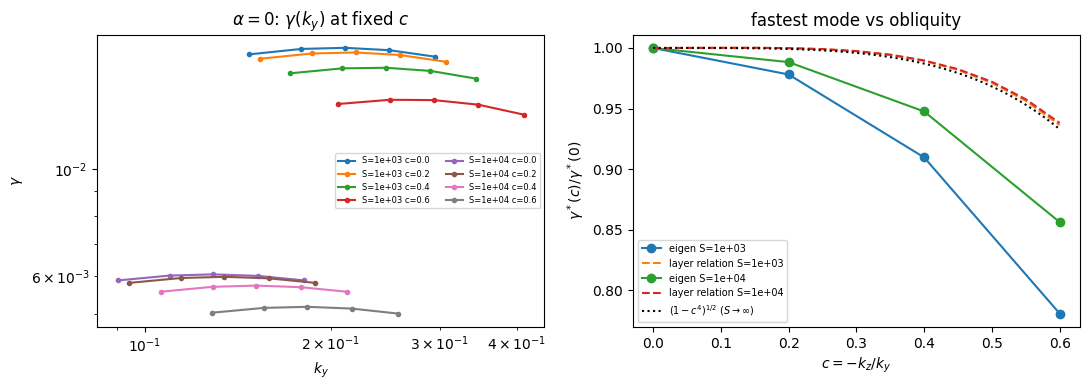

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for S in B.KMAX0_S:
    for (S_, Pm, c, fl, V, R), r in sorted(K0.items()):
        if S_ != S:
            continue
        ks = sorted(r["rows"])
        ax[0].plot(ks, [B.gamma(r["rows"][k]) for k in ks], "o-", ms=3, label=f"S={S:.0e} c={c}")
    cs = [k[2] for k in K0 if k[0] == S]
    ax[1].plot(sorted(cs), [R0[(S, 0.0, c, "none", 0.0, 1.0)] for c in sorted(cs)], "o-", label=f"eigen S={S:.0e}")
    cc = np.linspace(0, 0.6, 13)
    ax[1].plot(cc, [B.theory_kmax(c, S)[1]/B.theory_kmax(0.0, S)[1] for c in cc], "--", label=f"layer relation S={S:.0e}")
cc = np.linspace(0, 0.6, 50)
ax[1].plot(cc, (1 - cc**4)**0.5, "k:", label=r"$(1-c^4)^{1/2}$ ($S\to\infty$)")
ax[0].set(xscale="log", yscale="log", xlabel="$k_y$", ylabel=r"$\gamma$", title=r"$\alpha=0$: $\gamma(k_y)$ at fixed $c$")
ax[1].set(xlabel=r"$c=-k_z/k_y$", ylabel=r"$\gamma^*(c)/\gamma^*(0)$", title="fastest mode vs obliquity")
ax[0].legend(fontsize=6, ncol=2); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

**Result (4), question "fastest mode at $\alpha=0$".** At both $S=10^3$ and $10^4$ the fastest mode is at $k_z=0$:
$\gamma^*(c)/\gamma^*(0)=0.978,\,0.910,\,0.781$ ($S=10^3$) and $0.988,\,0.948,\,0.856$ ($S=10^4$) at $c=0.2,0.4,0.6$, against the layer relation's
$0.9998,\,0.989,\,0.936$ and the $S\to\infty$ asymptote $(1-c^4)^{1/2}=0.9992,\,0.987,\,0.933$. The eigenvalues fall off with $c$ faster than the
layer relation at these $S$ — the larger finite-$S$ correction of the oblique layer (section 3) — and approach it as $S$ grows (the gap at $c=0.6$
halves from $S=10^3$ to $10^4$: $1-0.781/0.936=0.17$, $1-0.856/0.938=0.087$). $k^*$ grows with $c$ as predicted ($k^*(0.6)/k^*(0)=1.41$ at $S=10^4$,
layer relation 1.42). So Baalrud et al.'s nonconstant-$\psi$ statement holds: the fastest mode over $k$ is $k_z=0$, with the theory's caveat that the margin is quartic at large $S$: at $S\to\infty$ every
$|c|\lesssim0.3$ grows within 1% of the fastest. $S=10^5$ scans were not run (cost); the $S$-trend above is from two decades only.

### 5. Field-aligned shear $u_0=\alpha b_0$ (pair, $S=10^4$, $\nu=0$)
By the exact reduction, $\mathrm{Re}\,\lambda(k_y,c)$ is the 2D aligned problem on the asymmetric sheet $f-c$ and $\mathrm{Im}\,\lambda=-k_y\alpha c+$
(intrinsic). The scans below answer question (i) — is the fastest mode still at $k_z=0$? — and give $\gamma^*(\alpha,c)/\gamma^*(0,c)$, the
shear factor at each obliquity (question ii: with aligned flow $\alpha_{loc}=\alpha$ identically, so any $c$-dependence of this factor comes from
$\Delta'(c)$ and $f'(x_s)$, not from a changed $\alpha$).

In [7]:
RA = scan_table(KA, "aligned")
print("\nshear factor gamma*(alpha, c)/gamma*(0, c) at S = 1e4 (denominator: the alpha = 0 scans of section 4):")
for (S, Pm, c, fl, V, R), r in sorted(KA.items()):
    r0 = K0.get((S, 0.0, c, "none", 0.0, 1.0))
    if r0:
        kn = min(r["rows"], key=lambda k: abs(k - r["kstar"]))
        lam = complex(r["rows"][kn]["lam"])
        print(f"  alpha = {V}  c = {c}: {r['gstar']/r0['gstar']:.5f}   (k*(alpha)/k*(0) = {r['kstar']/r0['kstar']:.4f}; "
              f"Im lambda at k = {kn:.4f}: {lam.imag:+.5f} vs -k alpha c = {-kn*V*c:+.5f})")

aligned:  S     Pm   flow  V    c   |  k*        gamma*        Im at k*      | gamma*(c)/gamma*(0) | points (nx max, worst conv)
   1e+04     0 tanh   0.6  0.0 | 0.16388  5.119893e-03  +6.55272e-18  |  1.00000       | 5 (16384, 4e-07)
   1e+04     0 tanh   0.9  0.0 | 0.22743  2.891280e-03  +1.17865e-13  |  1.00000       | 8 (32768, 1e-03)
   1e+04     0 tanh   0.6  0.2 | 0.17160  5.061932e-03  -1.87305e-02  |  0.98868       | 5 (16384, 1e-07)
   1e+04     0 tanh   0.6  0.4 | 0.19606  4.858903e-03  -4.47101e-02  |  0.94902       | 5 (16384, 4e-09)
   1e+04     0 tanh   0.9  0.4 | 0.27525  2.704111e-03  -9.34424e-02  |  0.93526       | 5 (32768, 1e-07)
   1e+04     0 tanh   0.6  0.6 | 0.24067  4.396773e-03  -9.17456e-02  |  0.85876       | 7 (16384, 7e-08)

shear factor gamma*(alpha, c)/gamma*(0, c) at S = 1e4 (denominator: the alpha = 0 scans of section 4):
  alpha = 0.6  c = 0.0: 0.84717   (k*(alpha)/k*(0) = 1.2800; Im lambda at k = 0.1574: +0.00000 vs -k alpha c = -0.00000)
  alpha = 

**Result (5), questions (i) and (ii) with aligned flow.** At $\alpha=0.6$ the fastest mode is still at $k_z=0$, and the obliquity dependence is almost
exactly that of $\alpha=0$: $\gamma^*(c)/\gamma^*(0)=0.989,\,0.949,\,0.859$ against $0.988,\,0.948,\,0.856$. Equivalently the **shear factor
$\gamma^*(0.6,c)/\gamma^*(0,c)=0.8472,\,0.8475,\,0.8485,\,0.8497$ is independent of $c$ to 0.3%**, i.e. the paper's $\alpha$-suppression carries over
unchanged to oblique modes (with aligned flow $\alpha_{loc}=\alpha$ identically; what this measures is that the suppression factor does not care that
$\Delta'$ and $f'(x_s)$ changed). $\mathrm{Im}\,\lambda=-k\alpha c$ to 0.6–1%: the mode is Doppler shifted by the flow at its surface, plus a small
intrinsic frequency of the asymmetric problem $f-c$ (+1.6e-4 to +5.7e-4 here). At $\alpha=0.9$ the shear factor is 0.478 ($c=0$) and 0.472 ($c=0.4$): $k_z=0$ is still fastest ($\gamma^*(0.4)/\gamma^*(0)=0.935$ vs 0.948
at $\alpha=0$), with a 1.3% $c$-dependence of the factor. The $\alpha=0.9$, $c=0$ scan is the least resolved in the notebook: its inviscid critical
layer is narrow, and its points converge to only $3$–$5\times10^{-6}$ near $k^*$ at $n_x=32768$ ($10^{-3}$ at the scan's high-$k$ end $k=0.61$, which does
not enter the parabola) — ample for the ratios quoted.
(Review check, 2026-10-03, with the independent Chebyshev code maximised over $k$ for the isolated sheet: $\gamma^*(c)$ decreases monotonically on a
finer grid, $c=0,0.05,0.1,0.15,0.2,0.3,0.4,0.6$ at $\alpha=0.6$ and $c=0,0.1,0.2,0.4,0.6$ at $\alpha=0.9$, so $k_z=0$ is the fastest mode between the
sampled $c$ too; by $\lambda(-c)=\overline{\lambda(c)}$ the same holds for $c<0$. Its $\alpha=0.9$, $c=0$ value, $2.88988\times10^{-3}$, agrees between
$N=500$ and 800 to $10^{-11}$.)

### 6. Non-aligned flow: does the shear act through $\alpha_{loc}(x_s)$?
$u=V\tanh(Rx)$ on the tanh pair, $k=0.5$, $S=10^4$: $\alpha_{loc}=VR\,\mathrm{sech}^2(Rx_s)/\mathrm{sech}^2x_s$ rises with $c$ for $(V,R)=(0.6,0.5)$
($0.30\to0.42$) and falls for $(0.3,2)$ ($0.60\to0.21$). Each point has an aligned twin $u=\alpha_{loc}(c)\,f$ at the same $(k,c)$. If the shear
acted only through the layer's $\alpha_{loc}$, flow/twin would be 1 at every $c$.

In [8]:
print(" (V, R)     c   alpha_loc | lambda (flow)                     lambda (aligned twin)             | Re ratio  | Im: flow, -k u(x_s)")
for V, R in B.LOCAL:
    for c in B.LOCAL_C:
        a = B.cfg_of("pair", B.SHEAR_S, 0.0, B.LAYER_K, c, "tanh", V, R, Lx=B.LAYER_LX)
        tw = B.cfg_of("pair", B.SHEAR_S, 0.0, B.LAYER_K, c, "tanh", float(np.round(B.alpha_loc(c, V, R), 8)), 1.0, Lx=B.LAYER_LX)
        if a in LOC and tw in LOC:
            la, lt = complex(LOC[a]["lam"]), complex(LOC[tw]["lam"])
            print(f" ({V}, {R})  {c:.1f}  {B.alpha_loc(c, V, R):.4f}   | {la:.8e}  {lt:.8e} | {la.real/lt.real:.4f}    | "
                  f"{la.imag:+.5f}, {B.doppler_of(c, B.LAYER_K, 'tanh', V, R):+.5f}")

 (V, R)     c   alpha_loc | lambda (flow)                     lambda (aligned twin)             | Re ratio  | Im: flow, -k u(x_s)
 (0.6, 0.5)  0.0  0.3000   | 4.57372312e-03+2.20653125e-18j  4.00280092e-03+2.92506075e-18j | 1.1426    | +0.00000, +0.00000
 (0.6, 0.5)  0.3  0.3219   | 5.04235981e-03-4.56086634e-02j  4.16239682e-03-4.76495026e-02j | 1.2114    | -0.04561, -0.04606
 (0.6, 0.5)  0.6  0.4167   | 6.81294935e-03-1.00017150e-01j  4.16967101e-03-1.23981380e-01j | 1.6339    | -0.10002, -0.10000
 (0.3, 2.0)  0.0  0.6000   | 1.48893029e-03+1.41827791e-15j  3.94884258e-03-9.03923191e-15j | 0.3771    | +0.00000, +0.00000
 (0.3, 2.0)  0.3  0.4596   | 3.44590215e-03-8.17957827e-02j  4.21598299e-03-6.81817471e-02j | 0.8173    | -0.08180, -0.08257
 (0.3, 2.0)  0.6  0.2076   | 3.96120121e-03-1.31539378e-01j  4.02705053e-03-6.16236385e-02j | 0.9836    | -0.13154, -0.13235


**Result (6), question (ii) with non-aligned flow: NO.** The growth rate is not set by $\alpha_{loc}(x_s)$: flow/twin is 1.14, 1.21, 1.63 for $(0.6,0.5)$
and 0.38, 0.82, 0.98 for $(0.3,2)$ at $c=0,0.3,0.6$ — far from 1 already at $c=0$, where the twin has the same local shear ratio $u'/f'$ at the
surface. The flow profile away from the surface (the outer region, and the second derivative $u''$ that enters the vorticity equation) matters as much
as the local ratio, as in Ofman et al.'s non-aligned 2D results. What *does* carry over is the frequency: $\mathrm{Im}\,\lambda=-k\,u_0(x_s)$ to $\le1\%$
for every non-aligned point. Caveat: the $(0.3,2)$, $c=0$ point did not converge in $n_x$ (last two rungs differ by $2\times10^{-4}$ at $n_x=32768$,
pair split $1.3\times10^{-3}$); its ratio 0.38 is good to that level only. (Review check: the independent
Chebyshev code, isolated sheet, $N=500$/800 identical, gives flow/twin $0.3769$ at $(0.3,2)$, $c=0$; $1.1426$ at $(0.6,0.5)$, $c=0$; $1.6341$ at
$(0.6,0.5)$, $c=0.6$ — the conclusion stands.)

### 7. The $P_m\gg1$ shear destabilisation, obliquely (sech2, $S=10^4$, $P_m=100$)
`tearing-viscosity.ipynb` found $\gamma^*(\alpha)/\gamma^*(0)=1.72,\,2.45,\,1.88$ at $\alpha=0.3,0.6,0.8$ for this sheet at $c=0$. Here
$\alpha=0.6$ at $c=0,0.2,0.4$ (each $\gamma^*$ by its own $k$ scan; $L_x=20/k$). The $c=0$ ratio is a consistency check against that notebook
(different grids and boxes: there $L_x=20/k_{th}$ for the whole family, here $L_x=20/k$ per point).

In [9]:
RV = scan_table(VI, "visc")
print()
for c in B.VISC_C:
    r0, r1 = VI.get((B.VISC_S, B.VISC_PM, c, "none", 0.0, 1.0)), VI.get((B.VISC_S, B.VISC_PM, c, "tanh", 0.6, 1.0))
    if r0 and r1:
        print(f"  c = {c}: gamma*(0.6)/gamma*(0) = {r1['gstar']/r0['gstar']:.4f}   (k* {r0['kstar']:.4f} -> {r1['kstar']:.4f})")
for key, r in sorted(VI.items()):
    xs = [x["x_peak"] - x["cfg"][8]/2 for x in r["rows"].values()]
    print(f"  {key}: current peak (x - Lx/2) of the leading vector over the scan: " + ", ".join(f"{v:+.3f}" for v in xs))

visc:  S     Pm   flow  V    c   |  k*        gamma*        Im at k*      | gamma*(c)/gamma*(0) | points (nx max, worst conv)
   1e+04   100 none     0  0.0 | 0.44272  9.471112e-03  -3.98137e-18  |  1.00000       | 5 (4096, 6e-15)
   1e+04   100 tanh   0.6  0.0 | 0.62150  2.319400e-02  +1.37021e-15  |  1.00000       | 5 (4096, 7e-14)
   1e+04   100 none     0  0.4 | 0.70975  9.223307e-03  -2.09884e-18  |  0.97384       | 5 (4096, 9e-15)
   1e+04   100 tanh   0.6  0.4 | 0.85393  1.807558e-02  -2.24912e-01  |  0.77932       | 5 (2048, 2e-15)

  c = 0.0: gamma*(0.6)/gamma*(0) = 2.4489   (k* 0.4427 -> 0.6215)
  c = 0.4: gamma*(0.6)/gamma*(0) = 1.9598   (k* 0.7097 -> 0.8539)
  (10000.0, 100.0, 0.0, 'none', 0.0, 1.0): current peak (x - Lx/2) of the leading vector over the scan: +0.000, +0.000, +0.000, +0.000, +0.000
  (10000.0, 100.0, 0.0, 'tanh', 0.6, 1.0): current peak (x - Lx/2) of the leading vector over the scan: +0.000, +0.000, +0.000, +0.000, +0.000
  (10000.0, 100.0, 0.4, 'none', 0.0

**Result (7), question (iii): the $P_m\gg1$ destabilisation survives obliquely, weakened.** At $c=0$ the scans reproduce `tearing-viscosity.ipynb`:
$\gamma^*(0)=9.4711\times10^{-3}$ (there $9.4724\times10^{-3}$, Newton $k_{max}$) and $\gamma^*(0.6)/\gamma^*(0)=2.4489$ (there 2.4490) — a
cross-notebook check through a different code path (3D blocks, per-point boxes, parabola maxima). At $c=0.4$ the ratio is **1.960**: shear still
roughly doubles the fastest growth, but less than at $c=0$, unlike the $P_m=0$ Harris case of section 5 where the shear factor did not move with $c$.
The oblique mode sits at the central surface ($x_s=-0.212$ for $c=0.4$; the leading vectors peak at $-0.21$ with flow, at $-0.17$ to $-0.18$ without,
where the viscous layer is broad), not at the tail surface, and $k^*$ grows a lot obliquely (0.44 → 0.71 at $\alpha=0$, 0.62 → 0.85 at $\alpha=0.6$).
Every ladder here converged by $n_x=2048$–$4096$ (successive rungs agree to $10^{-14}$), so the coarse-grid false growth of the Ofman study is not an
issue at $S_v=10^2$, $L_x=20/k$. Only $c=0,0.4$ were run (cost).

### 8. The $\alpha\to1$ low-$k$ mode, obliquely (sech2, $S=10^4$, $\nu=0$, $\alpha=1$)
At $\alpha=1$, $\nu=0$ the high-$k$ tearing branch is suppressed and the only growing mode is the low-$k$ branch of
`tearing-lowk-branch.ipynb` ($\gamma^*\propto S^{-0.66}$; Z$^-=0$ in 2D). By the reduction, obliquely it is the $\alpha=1$ aligned problem on
$f-c$ with a uniform flow $c$: Z$^-=u-b$ is then uniform, so the "no growth at $\nu=\eta$" theorem still applies, and at $\nu=0$ the mode
survives iff the asymmetric sheet $f-c$ carries it.

In [10]:
RL = scan_table(LK, "lowk")
print("\nreference (tearing-lowk-branch.ipynb, Newton k_max): S = 1e4, alpha = 1: k* = 0.267225, gamma* = 5.360668e-3")
print(f"\ncontinuation in c at k = {B.LOWK_K} (shift-invert, one eigenvalue, seeded by the previous c):")
TR = B.lowk_track(compute=False)
for nx, rows in TR.items():
    for c, v, res, xp in rows:
        print(f"  nx = {nx:5d}  c = {c:<7g} lambda = {v.real:+.6e} {v.imag:+.6e}i   (-k c = {-B.LOWK_K*c:+.5f}; x_peak - Lx/2 = {xp:+.3f})")
print("\ncoarse dense scans (seed grids) at c = 0.05 and 0.4: fastest eigenvalue per k")
for c in (0.05, 0.4):
    try:
        sc = B.coarse_scan("sech2", B.LOWK_S, 0.0, c, "tanh", 1.0, 1.0, compute=False)
        print(f"  c = {c}: " + "  ".join(f"k={k:.3f}: {v.real:.2e}{v.imag:+.3f}i" for k, v in sc.items() if v is not None))
    except KeyError:
        pass
print("\ndense spectra on a finer grid (the 4 fastest):")
for key, top in B.lowk_check(compute=False).items():
    print(f"  (c, k, nx) = {key}: " + ", ".join(f"{v.real:+.3e}{v.imag:+.4f}i" for v in top[:4]))

lowk:  S     Pm   flow  V    c   |  k*        gamma*        Im at k*      | gamma*(c)/gamma*(0) | points (nx max, worst conv)
   1e+04     0 tanh     1  0.0 | 0.26480  5.359492e-03  -1.59782e-13  |  1.00000       | 5 (8192, 2e-10)

reference (tearing-lowk-branch.ipynb, Newton k_max): S = 1e4, alpha = 1: k* = 0.267225, gamma* = 5.360668e-3

continuation in c at k = 0.265 (shift-invert, one eigenvalue, seeded by the previous c):
  nx =  2048  c = 0       lambda = +5.360146e-03 -4.411657e-15i   (-k c = -0.00000; x_peak - Lx/2 = -0.442)
  nx =  2048  c = 0.0025  lambda = +5.333832e-03 -2.123885e-04i   (-k c = -0.00066; x_peak - Lx/2 = -0.442)
  nx =  2048  c = 0.005   lambda = +5.254670e-03 -4.296972e-04i   (-k c = -0.00133; x_peak - Lx/2 = -0.442)
  nx =  2048  c = 0.01    lambda = +4.934931e-03 -9.012207e-04i   (-k c = -0.00265; x_peak - Lx/2 = -0.442)
  nx =  2048  c = 0.02    lambda = +3.638960e-03 -2.229846e-03i   (-k c = -0.00530; x_peak - Lx/2 = -0.442)
  nx =  2048  c = 0.03    lam

In [11]:
# (added by the adversarial review, 2026-10-03) the identity of the c = 0.05, k ~ 0.61 mode: continuations from it
P = B.lowk_paths(compute=False)
print(f"lowk_paths (nx = {B.LOWK_PATH_ANCHOR[2]}, Lx = 20/k), seeded at (c, k) = {B.LOWK_PATH_ANCHOR[:2]}:")
print("  in c at k = %.5f, down to c = 0:" % B.LOWK_PATH_ANCHOR[1])
for c, v, res, xp in P["c"]:
    print(f"    c = {c:<6g} lambda = {v.real:.6e} {v.imag:+.6e}i   (residual {res:.0e}, x_peak - Lx/2 = {xp:+.3f})")
print("  in k at c = %g:" % B.LOWK_PATH_ANCHOR[0])
for k, v, res, xp in P["k"]:
    print(f"    k = {k:<7g} lambda = {v.real:.6e} {v.imag:+.6e}i   (residual {res:.0e}, x_peak - Lx/2 = {xp:+.3f})")
print("  the anchor at higher resolution / doubled box:")
for nx, Lx, v, res in P["conv"]:
    print(f"    nx = {nx:5d}, Lx = {Lx:.3f}: lambda = {v.real:.7e} {v.imag:+.7e}i")
sc0 = B.coarse_scan("sech2", B.LOWK_S, 0.0, 0.0, "tanh", 1.0, 1.0, compute=False)
print(f"  c = 0 seed grid at k = {B.LOWK_PATH_ANCHOR[1]}: {sc0[B.LOWK_PATH_ANCHOR[1]]:.6e} (the low-k branch's gamma(k) at c = 0)")

lowk_paths (nx = 4096, Lx = 20/k), seeded at (c, k) = (0.05, 0.60976):
  in c at k = 0.60976, down to c = 0:
    c = 0.05   lambda = 1.722072e-03 -2.936131e-02i   (residual 3e-15, x_peak - Lx/2 = -0.440)
    c = 0.04   lambda = 1.903687e-03 -2.339975e-02i   (residual 8e-16, x_peak - Lx/2 = -0.432)
    c = 0.03   lambda = 2.075715e-03 -1.748292e-02i   (residual 2e-15, x_peak - Lx/2 = -0.424)
    c = 0.02   lambda = 2.223297e-03 -1.161323e-02i   (residual 5e-15, x_peak - Lx/2 = -0.424)
    c = 0.015  lambda = 2.282774e-03 -8.695304e-03i   (residual 3e-14, x_peak - Lx/2 = -0.416)
    c = 0.01   lambda = 2.329797e-03 -5.787665e-03i   (residual 1e-14, x_peak - Lx/2 = -0.416)
    c = 0.005  lambda = 2.361952e-03 -2.889430e-03i   (residual 4e-12, x_peak - Lx/2 = -0.408)
    c = 0      lambda = 2.374976e-03 +2.230345e-13i   (residual 2e-12, x_peak - Lx/2 = +0.408)
  in k at c = 0.05:
    k = 0.60976 lambda = 1.722072e-03 -2.936131e-02i   (residual 3e-15, x_peak - Lx/2 = -0.440)
    k = 0.55   

**Result (8), question (iv): the low-$k$ branch survives obliquely, but its peak is strongly suppressed and moves to higher $k$.**
(Corrected by the adversarial review, 2026-10-03; the implementer's version read "does not survive obliquity, identity open".)
At $c=0$ the scan reproduces `tearing-lowk-branch.ipynb` ($\gamma^*=5.3595\times10^{-3}$ at $k^*=0.2648$ vs $5.3607\times10^{-3}$ at $0.2672$; the
five-point parabola sits $\sim10^{-4}$ low — the $c=0$ track value at $k=0.265$ is $5.3601\times10^{-3}$).
Followed continuously in $c$ at $k=0.265$, the growth rate falls quadratically at first and then fast: $5.360\to5.334\to5.255\to4.935\to3.639
\to1.949\times10^{-3}$ at $c=0,0.0025,0.005,0.01,0.02,0.03$ (identical at $n_x=2048$ and 4096 to $<10^{-8}$ through $c=0.02$, $5\times10^{-6}$ at 0.03),
and $\approx7\times10^{-4}$ at $c=0.05$ ($8.5$ vs $6.9\times10^{-4}$ at $n_x=2048$, 4096; a review run at $n_x=8192$, 16384 gives $7.17$, $7.16\times10^{-4}$).
For comparison the tearing mode of section 4 loses 1.2% at $c=0.2$.
**The $c=0.05$, $k\approx0.61$ mode is the same branch** (cell above, `B.lowk_paths`): followed in $c$ at $k=0.61$ it continues smoothly to a real
eigenvalue at $c=0$, $2.375\times10^{-3}$, which is the $c=0$ seed grid's value of the low-$k$ branch at that $k$ (its high-$k$ flank), with the current
peak staying at $|x|\approx0.41$–$0.44$; followed in $k$ at $c=0.05$ it continues smoothly down to the $k=0.265$ value of the $c$-track ($6.91\times10^{-4}$
at $n_x=4096$). The anchor is converged ($1.72186\times10^{-3}$ at $n_x=8192$ and 16384, $1.72207\times10^{-3}$ at 4096) and box-independent
($1.72215\times10^{-3}$ at $L_x=40/k$). So obliquity suppresses the branch **unevenly in $k$**: at $c=0.05$ it keeps 73% of its $c=0$ growth at
$k=0.61$ but 13% at $k=0.265$, and its maximum moves to $k\approx0.55$, $\gamma\approx1.78\times10^{-3}$ (33% of the $c=0$ maximum; $n_x=4096$).
$\mathrm{Im}\,\lambda\approx-kc$ throughout (the Doppler shift of the uniform flow $c$ of the reduced problem).
At $c=0.2$ and 0.4 the fastest eigenvalues on the finer dense grids are weak ($\le4.3\times10^{-4}$ at $k=0.265$) and, at $c=0.4$, $k=0.855$,
grid-dependent ($3.5\to7.5\times10^{-4}$ from $n_x=2048$ to 4096): unresolved critical-layer/continuum candidates of the $\nu=0$ problem, which we do not
claim are physical, and the branch was not followed beyond $c=0.05$. (The reviewer's independent Chebyshev code does **not** resolve this $\alpha=1$,
$\nu=0$ problem — it scatters by tens of per cent with $N$ even at $c=0$ — so these values rest on the taranis ladders and their $n_x$/box checks alone.)
Within the reduction, the $\alpha=1$ problem at $c$ is the 2D field-aligned problem on the sheet $f-c$ with a uniform flow $c$; a theory of the low-$k$
branch should explain why a uniform $B_y$ offset of a few per cent removes its peak but not its high-$k$ flank. For the JPP paper's "complete
stabilisation" caveat: obliquely the $\alpha\to1$, $\nu=0$ growth persists at a reduced level (a third of the $c=0$ maximum at $|k_z/k_y|=0.05$); how far
in $c$ it persists is open.

### 9. Summary

| question | answer (S = 10^4 unless stated) |
|---|---|
| fastest mode, $\alpha=0$ (Harris) | $k_z=0$; $\gamma^*(c)/\gamma^*(0)=0.988,\,0.948,\,0.856$ at $c=0.2,0.4,0.6$ ($S=10^3$: 0.978, 0.910, 0.781); layer relation 0.9999, 0.990, 0.938; $S\to\infty$: $(1-c^4)^{1/2}$ (exact within the layer relation) |
| fastest mode, aligned shear | still $k_z=0$ at $\alpha=0.6$ and 0.9; the $c$-dependence is that of $\alpha=0$ to 0.3% ($\alpha=0.6$) |
| $\alpha$-suppression at $x_s$ | aligned: exact by the reduction ($\alpha_{loc}\equiv\alpha$); measured shear factor 0.847–0.850 for $c=0$–0.6 at $\alpha=0.6$, 0.478/0.472 at $\alpha=0.9$, $c=0/0.4$. Non-aligned: **no** — flow/aligned-twin at equal $\alpha_{loc}$ is 0.38–1.63 |
| frequency | $\mathrm{Im}\,\lambda=-k\,u_0(x_s)$ to $\le1\%$, aligned and non-aligned (exact up to the intrinsic frequency of $f-c$ for aligned flow) |
| $P_m=100$ destabilisation (sech2) | survives: $\gamma^*(0.6)/\gamma^*(0)=2.449$ at $c=0$ (reproduces `tearing-viscosity`), 1.960 at $c=0.4$ |
| $\alpha\to1$ low-$k$ mode (sech2, $\alpha=1$) | survives, unevenly in $k$: $\gamma(k=0.265)$ halves by $c\approx0.025$ and is 13% of its $c=0$ value at $c=0.05$, but the branch's high-$k$ flank keeps 73% at $k=0.61$; at $c=0.05$ the maximum is $\approx1.78\times10^{-3}$ at $k\approx0.55$ (33% of the $c=0$ maximum; same branch, by continuation in $c$ and in $k$). Beyond $c=0.05$: open |
| asymmetric current sheet (theory only) | fastest surface oblique: $c^*=0.344$ for $f=\tanh x+0.3\,\mathrm{sech}^2x$, 2.8% above $c=0$ at large $S$; **no eigen-solve checks this** |

Exact gates (a)–(d) and the helpers: `tests/test_tearing_oblique.py`. Independent routes: the one-sheet FD code reproduces three ladder eigenvalues to
$\le10^{-5}$ (two) and the doubled-box value (one); the review's Chebyshev code (gated in the test file) reproduces the doubled-box value to $1.4\times10^{-8}$,
the exact reduction with a non-aligned flow to $3\times10^{-8}$, and every $\gamma^*$ ratio of sections 4, 5 and 7 to $\le2\times10^{-4}$. **Not done:** $S=10^5$ $k$-scans (the $S$-trend of the oblique finite-$S$ correction rests on
$S=10^3,10^4$ scans and the fixed-$k$ layer series to $10^5$); non-aligned flows at other $k$; $P_m=100$ at more $c$ and $\alpha$; a layer theory
for the oblique finite-$S$ correction; eigen-solves of the asymmetric sheet; the weak $c\ge0.05$, $\alpha=1$ modes.